# Visualisation : signaux, normalisation et images GASF / GADF

Ce notebook montre comment un signal de roulement (5000 points) est transformé en image
**Gramian Angular Field** avant d'être donné au Conv2D et au réseau siamois de `main.ipynb`.

- **GASF** (summation) : cos(φᵢ + φⱼ)
- **GADF** (difference) : sin(φᵢ − φⱼ)

où φ = arccos(x) après normalisation du signal dans [-1, 1].

In [1]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from pyts.image import GramianAngularField

from bearing_utils import CLASS_NAMES, load_signals, minmax, zscore

# Images en JPEG pour garder un notebook léger
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["savefig.dpi"] = 80

DATASET_DIR = Path(os.environ.get("DATASET_DIR", "Dataset"))
X_raw, y, SOURCE = load_signals(DATASET_DIR, max_per_class=3)
print("Source :", SOURCE, "| signaux chargés :", X_raw.shape)

SHORT = {"Normal": "Normal", "Inner Race Fault": "IRF (bague intérieure)", "Outer Race Fault": "ORF (bague extérieure)"}
COLORS = ["green", "orange", "red"]
first = {c: np.where(y == c)[0][0] for c in range(len(CLASS_NAMES))}

Source : jeu de démonstration (data/demo) | signaux chargés : (9, 5000)


## 1. Signaux bruts des 3 classes

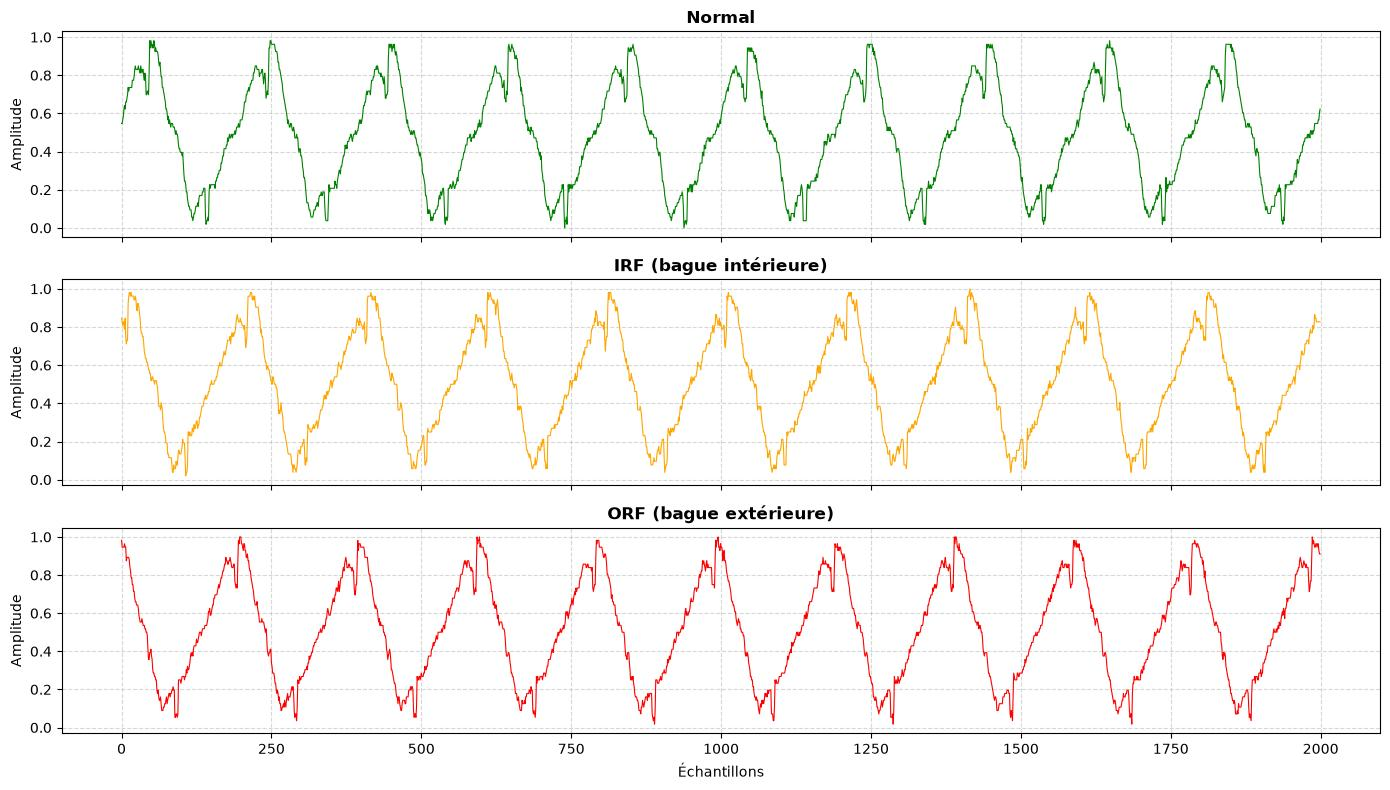

In [2]:
N_POINTS = 2000
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for c, name in enumerate(CLASS_NAMES):
    axes[c].plot(X_raw[first[c], :N_POINTS], color=COLORS[c], linewidth=0.8)
    axes[c].set_title(SHORT[name], fontweight="bold")
    axes[c].set_ylabel("Amplitude")
    axes[c].grid(True, linestyle="--", alpha=0.5)
axes[-1].set_xlabel("Échantillons")
plt.tight_layout()
plt.show()

## 2. Normalisation

- **Min-Max [0, 1]** : utilisée avant la transformation GAF.
- **Standardisation** (moyenne 0, écart-type 1) : utilisée pour le Conv1D.

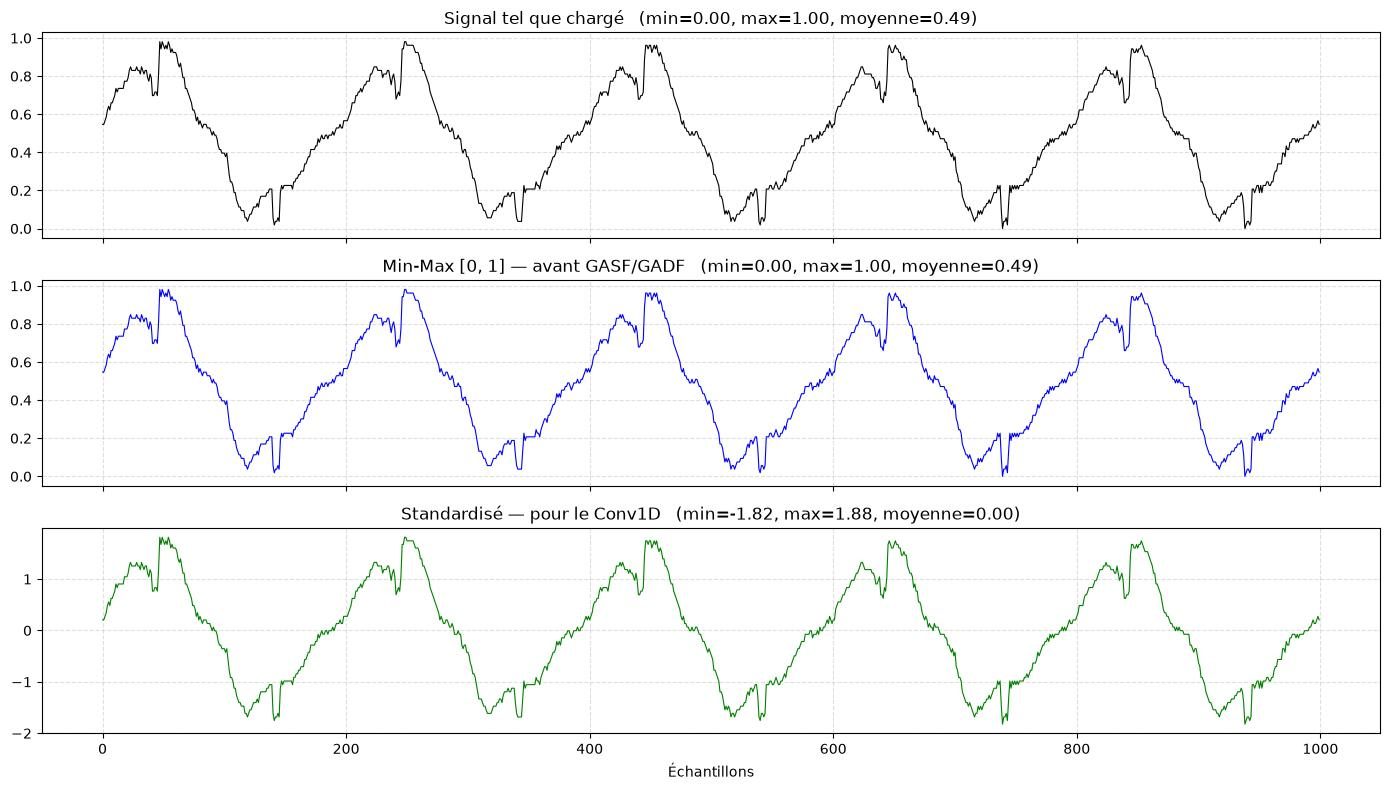

In [3]:
signal = X_raw[first[0]:first[0] + 1]
variants = [
    ("Signal tel que chargé", signal[0], "black"),
    ("Min-Max [0, 1] — avant GASF/GADF", minmax(signal)[0], "blue"),
    ("Standardisé — pour le Conv1D", zscore(signal)[0], "green"),
]
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (title, s, color) in zip(axes, variants):
    ax.plot(s[:1000], color=color, linewidth=0.8)
    ax.set_title(f"{title}   (min={s.min():.2f}, max={s.max():.2f}, moyenne={s.mean():.2f})")
    ax.grid(True, linestyle="--", alpha=0.4)
axes[-1].set_xlabel("Échantillons")
plt.tight_layout()
plt.show()

## 3. Images GASF et GADF par classe

Le signal **complet** (5000 points) est réduit à `IMAGE_SIZE` points par moyenne par blocs (PAA)
avant le calcul de l'image, exactement comme dans `main.ipynb`.

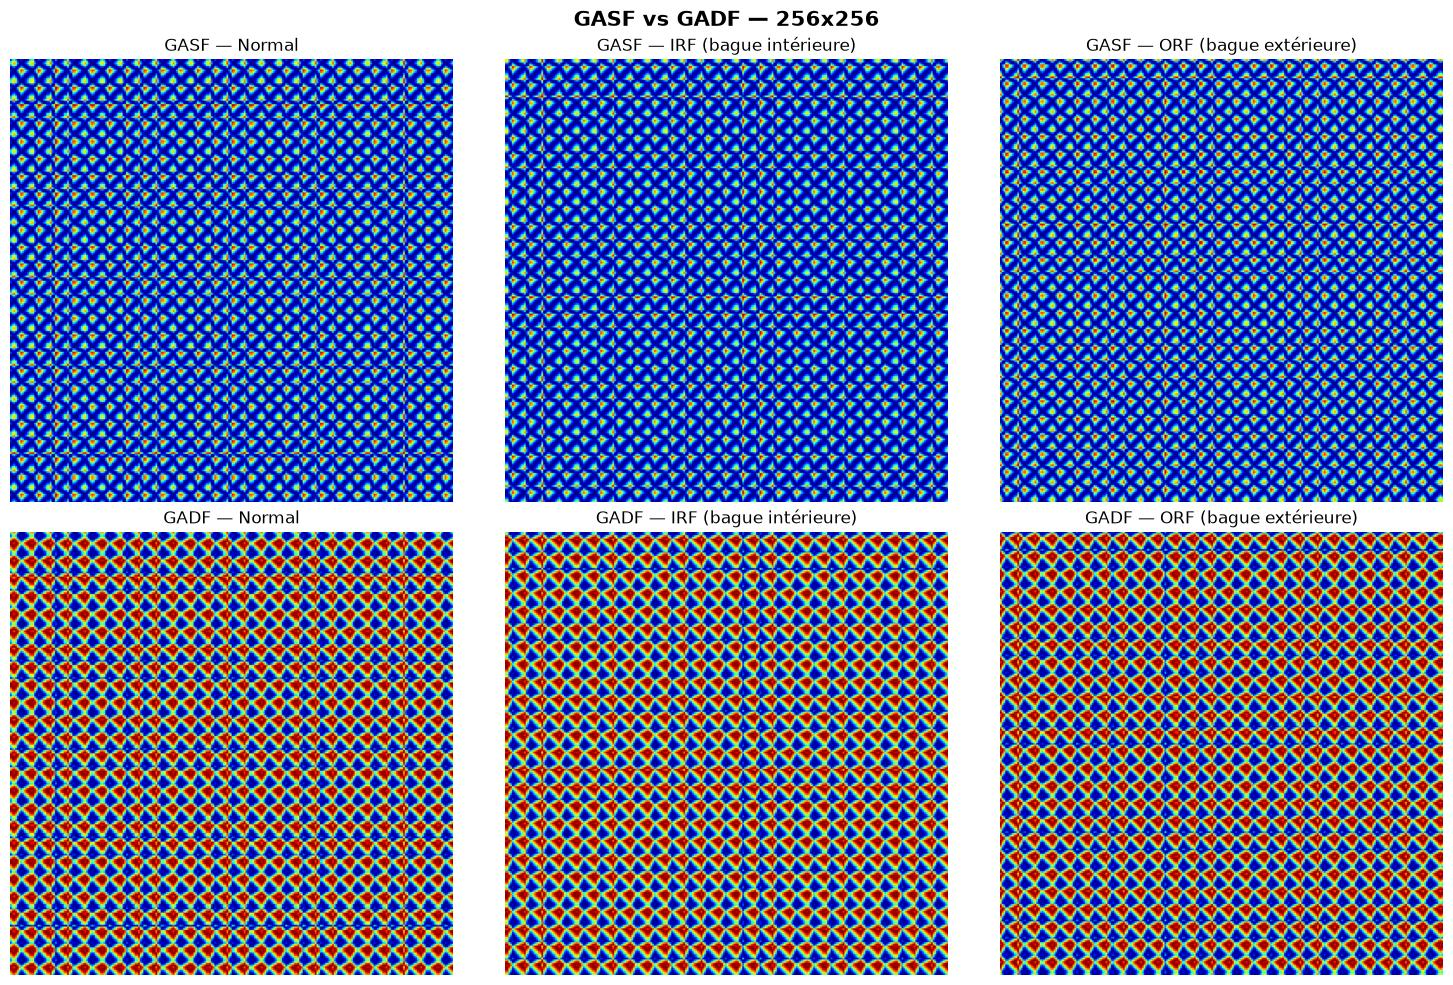

In [4]:
IMAGE_SIZE = 256   # 1024 dans l'étude complète
X_mm = minmax(X_raw)
gasf = GramianAngularField(method="summation", image_size=IMAGE_SIZE)
gadf = GramianAngularField(method="difference", image_size=IMAGE_SIZE)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle(f"GASF vs GADF — {IMAGE_SIZE}x{IMAGE_SIZE}", fontsize=15, fontweight="bold")
for c, name in enumerate(CLASS_NAMES):
    sig = X_mm[first[c]:first[c] + 1]
    axes[0, c].imshow(gasf.fit_transform(sig)[0], cmap="jet")
    axes[0, c].set_title(f"GASF — {SHORT[name]}")
    axes[1, c].imshow(gadf.fit_transform(sig)[0], cmap="jet")
    axes[1, c].set_title(f"GADF — {SHORT[name]}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Plusieurs signaux par classe (GASF)

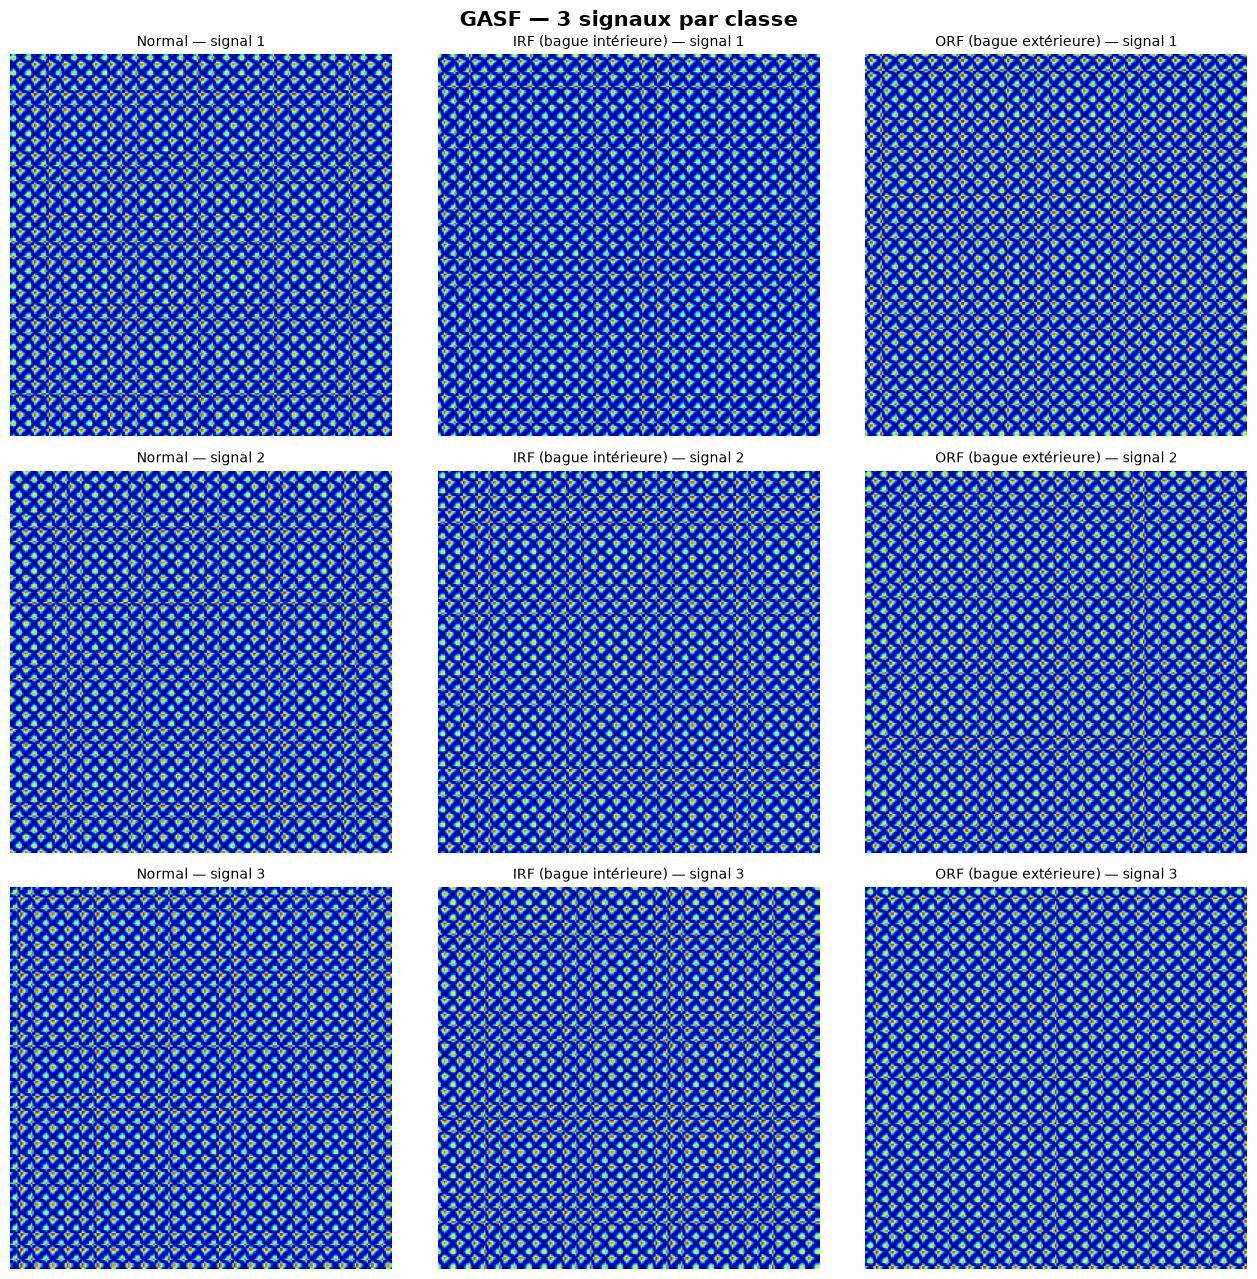

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
fig.suptitle("GASF — 3 signaux par classe", fontsize=15, fontweight="bold")
for c, name in enumerate(CLASS_NAMES):
    for row, i in enumerate(np.where(y == c)[0][:3]):
        axes[row, c].imshow(gasf.fit_transform(X_mm[i:i + 1])[0], cmap="jet")
        axes[row, c].set_title(f"{SHORT[name]} — signal {row + 1}", fontsize=10)
        axes[row, c].axis("off")
plt.tight_layout()
plt.show()

## 5. Influence de la résolution de l'image

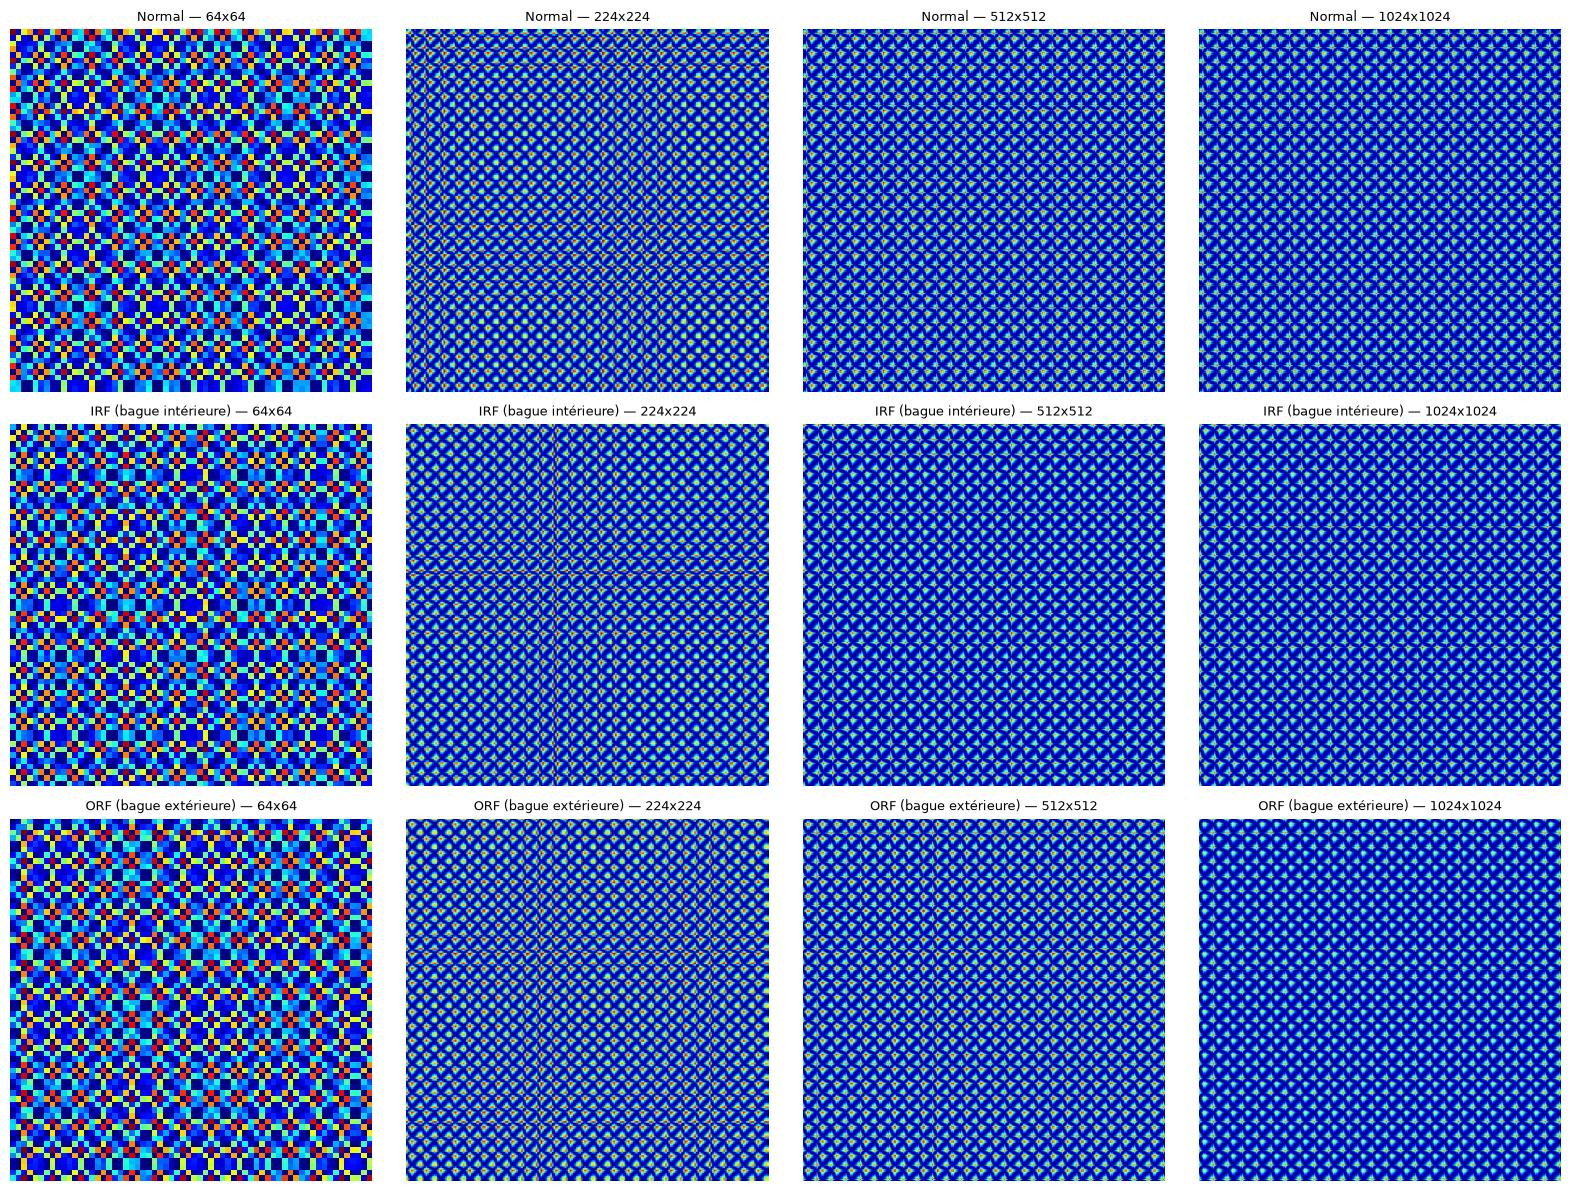

In [6]:
sizes = [64, 224, 512, 1024]
fig, axes = plt.subplots(len(CLASS_NAMES), len(sizes), figsize=(4 * len(sizes), 12))
for c, name in enumerate(CLASS_NAMES):
    sig = X_mm[first[c]:first[c] + 1]
    for j, size in enumerate(sizes):
        img = GramianAngularField(method="summation", image_size=size).fit_transform(sig)[0]
        axes[c, j].imshow(img, cmap="jet")
        axes[c, j].set_title(f"{SHORT[name]} — {size}x{size}", fontsize=9)
        axes[c, j].axis("off")
plt.tight_layout()
plt.show()